# Exploring Radio Signals and Classifying Fashion Images
**DASC 3230 · Individual project 3 · Weeks 7–9**

Explore structure in radio-signal candidates, screen candidates against a
background reference, and build a small image classifier.

Complete **12 TODOs**, **three code-reading responses (S1–S3)**, and
**three result responses (R1–R3)**. Keep written answers brief and refer to
your code or displayed results.

Use NumPy, Matplotlib, PyTorch, and only PCA and KernelDensity from scikit-learn.
Implement the K-means assignment and centre update with NumPy.
Keep the supplied data, seeds, settings, and checks. Replace each
NotImplementedError with your code.

| Part | Topic | Marks |
|---|---|---:|
| A | PCA and K-means | 35 |
| B | Density estimation and candidate screening | 30 |
| C | Image classification with a CNN | 35 |
| **Total** | | **100** |

The supplied helpers handle data splitting, cross-validation, training,
and most plotting. Marks are based on your implementation and explanations;
there is no minimum accuracy requirement.

See [data/README.pdf](data/README.pdf) for data sources and feature descriptions.
Submit one A4 PDF containing the completed notebook, code, outputs, and answers.


In [1]:
from pathlib import Path
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.decomposition import PCA
from sklearn.neighbors import KernelDensity

SEED = 3230
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
plt.rcParams.update({"font.size": 10, "figure.dpi": 100})

PROJECT_DIR = Path.cwd()
print(PROJECT_DIR)
if not (PROJECT_DIR / "data" / "htru2_small.npz").exists():
    PROJECT_DIR = PROJECT_DIR.parent / "individual_project_3"
DATA_DIR = PROJECT_DIR / "data"
assert DATA_DIR.is_dir(), "Open the notebook from its project folder."

def fit_standardizer(X):
    mean = X.mean(axis=0)
    scale = X.std(axis=0, ddof=0)
    scale = np.where(scale == 0, 1., scale)
    return mean, scale

def apply_standardizer(X, mean, scale):
    return (X - mean) / scale


/Users/perislyimo/Desktop/DASC 3230/PROJECTS/individual_project_3


## A. HTRU2: structure in radio candidates — 35 marks

Each row describes one radio-signal candidate. We use four features:
the mean and standard deviation of its pulse profile, and the mean and
standard deviation of its DM–SNR curve. These summaries are already computed.

For PCA and clustering, use the mixed training sample. The class labels
are shown later to help interpret the groups: 0 is a background candidate
(non-pulsar), and 1 is a pulsar candidate.


In [2]:
with np.load(DATA_DIR / "htru2_small.npz", allow_pickle=False) as data:
    radio_X_train = data["X_train"]
    radio_y_train = data["y_train"]
assert radio_X_train.shape == (1650, 4)
assert radio_y_train.shape == (1650,)
explore_mean, explore_scale = fit_standardizer(radio_X_train)
radio_U_train = apply_standardizer(radio_X_train, explore_mean, explore_scale)
print("Training observations and features:", radio_U_train.shape)


Training observations and features: (1650, 4)


### Two PCA coordinates
**TODO 1 (6 marks):** Fit a two-component PCA to U, which has already been standardized by the supplied code.
U has shape (n, p).
**Return (pca, Z, retained), in this order:**
the fitted PCA object, a NumPy score array of shape (n, 2), and the scalar
sum of the two explained variance ratios.


In [3]:
def fit_pca(U):
    # TODO 1
    pca = PCA(n_components=2)
    Z = pca.fit_transform(U)                      # scores, shape (n, 2)
    retained = float(np.sum(pca.explained_variance_ratio_))
    return pca, Z, retained

toy_U = np.array([[-2., -2.], [-1., -1.], [1., 1.], [2., 2.]])
toy_pca, toy_Z, toy_retained = fit_pca(toy_U)
assert toy_Z.shape == (4, 2)
assert toy_pca.components_.shape == (2, 2)
assert np.isclose(toy_retained, 1.0)

radio_pca, radio_Z_train, radio_retained = fit_pca(radio_U_train)
assert radio_Z_train.shape == (1650, 2)
print("Variance ratios:", np.round(radio_pca.explained_variance_ratio_, 4))
print(f"Retained variance: {radio_retained:.2%}")


Variance ratios: [0.5134 0.3396]
Retained variance: 85.30%


**TODO 2 (5 marks):** reconstruct the standardized features from their PCA
scores and calculate the reconstruction MSE.
Given U of shape (n, p), scores Z of shape (n, 2), and the fitted pca,
**return (rebuilt, error)**.
rebuilt is the NumPy reconstruction of shape (n, p); error is its scalar
mean squared error over all entries of U. Use standardized feature units.


In [4]:
def reconstruct_pca(U, Z, pca):
    # TODO 2
    rebuilt = pca.inverse_transform(Z)            # Z @ components_ + mean_, shape (n, p)
    error = float(np.mean((U - rebuilt) ** 2))    # mean over all n * p entries
    return rebuilt, error

toy_rebuilt, toy_error = reconstruct_pca(toy_U, toy_Z, toy_pca)
assert np.allclose(toy_rebuilt, toy_U) and np.isclose(toy_error, 0)
partial_pca = PCA(n_components=2).fit(np.vstack([np.eye(3), -np.eye(3)]))
check_U = np.vstack([np.eye(3), -np.eye(3)])
_, partial_error = reconstruct_pca(check_U, partial_pca.transform(check_U), partial_pca)
assert np.isclose(partial_error, 1 / 9)

radio_U_rebuilt, radio_reconstruction_mse = reconstruct_pca(
    radio_U_train, radio_Z_train, radio_pca)
assert radio_U_rebuilt.shape == radio_U_train.shape
print(f"Standardized reconstruction MSE: {radio_reconstruction_mse:.4f}")


Standardized reconstruction MSE: 0.1470


### K-means on four standardized features
**TODO 3 (6 marks):** assign each observation to its nearest centroid using
squared Euclidean distance.
Given U of shape (n, p) and centres of shape (K, p), **return labels**,
an integer NumPy array of shape (n,) containing centroid indices from 0 to K - 1.
In a tie, choose the first centroid.

**TODO 4 (6 marks):** update each cluster centre using the mean of its assigned
observations.
Given U of shape (n, p), labels of shape (n,), and old_centres of shape (K, p),
**return a new NumPy array of shape (K, p)** containing the updated centres.
Keep the previous centre for an empty cluster, and leave old_centres unchanged.


In [5]:
def assign_clusters(U, centres):
    # TODO 3
    # (n, 1, p) - (1, K, p) -> (n, K, p); sum over features -> (n, K)
    sq_dist = np.sum((U[:, None, :] - centres[None, :, :]) ** 2, axis=2)
    return np.argmin(sq_dist, axis=1).astype(int)  # argmin picks the first index in a tie

check_U = np.array([[0., 0.], [2., 0.], [4., 2.]])
check_centres = np.array([[0., 0.], [4., 0.]])
assert np.array_equal(assign_clusters(check_U, check_centres), [0, 0, 1])
assert assign_clusters(check_U, check_centres).shape == (3,)
print("Assignment check passed.")


Assignment check passed.


In [6]:
def update_centres(U, labels, old_centres):
    # TODO 4
    new_centres = np.array(old_centres, dtype=float, copy=True)  # never modify the input
    for k in range(len(old_centres)):
        members = U[labels == k]
        if len(members) > 0:                      # empty cluster keeps its old centre
            new_centres[k] = members.mean(axis=0)
    return new_centres

check_old = np.array([[9., 9.], [4., 0.], [-3., 5.]])
check_new = update_centres(check_U, np.array([0, 0, 1]), check_old)
assert np.allclose(check_new, [[1., 0.], [4., 2.], [-3., 5.]])
assert np.allclose(check_old, [[9., 9.], [4., 0.], [-3., 5.]])
print("Centre update check passed.")


Centre update check passed.


The supplied driver runs your two steps from ten fixed initializations and
keeps the result with the smallest inertia. K is fixed at 2.
PCA supplies the coordinates for the display; clustering uses all four features.


Cluster  Background  Pulsar  Total
      0          86     112    198
      1        1414      38   1452


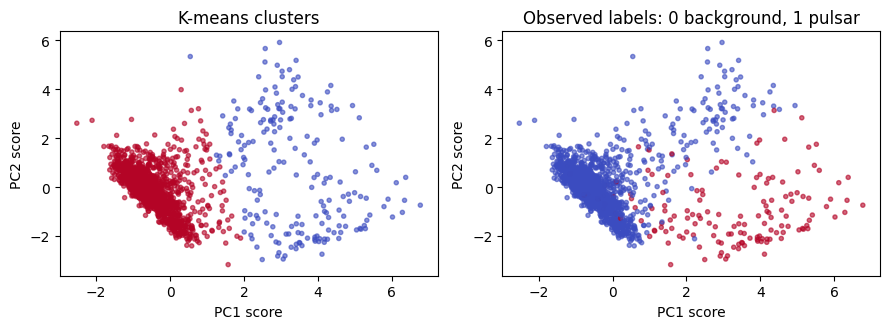

In [7]:
def run_kmeans(U, K=2, seed=SEED):
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(10):
        centres = U[rng.choice(len(U), K, replace=False)].copy()
        for _ in range(100):
            labels = assign_clusters(U, centres)
            updated = update_centres(U, labels, centres)
            converged = np.allclose(updated, centres, rtol=0, atol=1e-8)
            centres = updated
            if converged:
                break
        labels = assign_clusters(U, centres)
        inertia = float(np.sum((U - centres[labels]) ** 2))
        if best is None or inertia < best["inertia"]:
            best = {"centres": centres.copy(), "labels": labels.copy(),
                    "inertia": inertia}
    return best

radio_clusters = run_kmeans(radio_U_train)
cluster_table = []
print("Cluster  Background  Pulsar  Total")
for k in range(2):
    mask = radio_clusters["labels"] == k
    row = {"cluster": k, "background": int(np.sum(radio_y_train[mask] == 0)),
           "pulsar": int(np.sum(radio_y_train[mask] == 1)), "total": int(mask.sum())}
    cluster_table.append(row)
    print(f'{k:7d} {row["background"]:11d} {row["pulsar"]:7d} {row["total"]:6d}')

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, colour, title in zip(
        axes, [radio_clusters["labels"], radio_y_train],
        ["K-means clusters", "Observed labels: 0 background, 1 pulsar"]):
    ax.scatter(radio_Z_train[:, 0], radio_Z_train[:, 1], c=colour,
               cmap="coolwarm", s=9, alpha=.6)
    ax.set(xlabel="PC1 score", ylabel="PC2 score", title=title)
fig.tight_layout()
plt.show()


**S1 (5 marks).**

(a) What do the rows and two columns of radio_Z_train represent?
How do these scores differ from the K-means labels?

(b) Why standardize the features before distance-based clustering?

**Answer:**

(a) Each **row** of radio_Z_train is one training candidate (1,650 rows). The two **columns** are its
PC1 and PC2 scores: projections of its four standardized features onto the two directions of greatest
variance. The scores are continuous coordinates. A K-means label is a single integer (0 or 1) saying
which centroid is nearest in the full four-feature space. PCA gives a position; K-means gives a group.

(b) K-means uses squared Euclidean distance, so features with large numeric ranges would dominate it.
The raw features have very different spreads: profile_std has a standard deviation of about 7, but
dm_snr_mean has one of about 32, so it would dominate the distances unscaled. Standardizing gives
every feature mean 0 and standard deviation 1, so each contributes on a comparable scale.

**R1 (7 marks).**

(a) Report the retained variance and reconstruction MSE.
What do they tell you about using two coordinates instead of four?

(b) Does one cluster contain only background candidates and the other only
pulsar candidates? Use the counts in the table to support your answer.

**Answer:**

(a) The two components retain **85.30%** of the variance (PC1 51.34%, PC2 33.96%), and the
standardized reconstruction MSE is **0.1470**. Two coordinates keep most of the structure and are good
for a 2-D display. About 15% of the variance is lost, which shows up as average squared reconstruction
error of about 0.15 standardized units per entry. So the plot is a good summary, not a perfect copy.

(b) No. Cluster 0 has 86 background and 112 pulsar candidates (198 total). Cluster 1 has 1,414 background
and 38 pulsar candidates (1,452 total). Cluster 0 is enriched in pulsars (112/198, about 57%, compared with
150/1650, about 9%, overall). Neither cluster is pure: 86 background candidates sit in cluster 0, and
38 of the 150 pulsars (about 25%) fall in the mostly background cluster 1. K-means groups by
feature similarity, not by the labels.

## B. HTRU2: screening against a background reference — 30 marks

We now fit a density using only background training candidates.
The two features are pulse-profile mean and standard deviation.
The standardization mean and scale are estimated from this reference sample.

Training folds select the bandwidth. The separate background calibration
sample sets the threshold. Test labels are used for the final evaluation.


In [8]:
background_X = radio_X_train[radio_y_train == 0, :2]
density_mean, density_scale = fit_standardizer(background_X)
background_U = apply_standardizer(background_X, density_mean, density_scale)
with np.load(DATA_DIR / "htru2_small.npz", allow_pickle=False) as data:
    calibration_U = apply_standardizer(
        data["X_calibration"][:, :2], density_mean, density_scale)
assert background_U.shape == (1500, 2) and calibration_U.shape == (400, 2)

BANDWIDTHS = np.array([0.1, 0.3, 1.0])
indices = np.random.default_rng(SEED).permutation(len(background_X))
validation_folds = np.array_split(indices, 3)
folds = []
for k in range(3):
    val_idx = validation_folds[k]
    fit_idx = np.concatenate(validation_folds[:k] + validation_folds[k + 1:])
    folds.append((fit_idx, val_idx))
cv_log_density = np.empty((len(BANDWIDTHS), len(folds)))
for j, h in enumerate(BANDWIDTHS):
    for k, (fit_idx, val_idx) in enumerate(folds):
        fold_mean, fold_scale = fit_standardizer(background_X[fit_idx])
        fit_U = apply_standardizer(background_X[fit_idx], fold_mean, fold_scale)
        val_U = apply_standardizer(background_X[val_idx], fold_mean, fold_scale)
        fold_kde = KernelDensity(kernel="gaussian", bandwidth=float(h)).fit(fit_U)
        cv_log_density[j, k] = fold_kde.score_samples(val_U).mean()
print("Rows: bandwidths; columns: held-out training folds")
print(np.round(cv_log_density, 4))


Rows: bandwidths; columns: held-out training folds
[[-3.2644 -3.0569 -2.9938]
 [-2.7847 -2.6813 -2.6748]
 [-2.9932 -2.9514 -2.9545]]


**TODO 5 (5 marks):** implement select_bandwidth to choose a KDE bandwidth
using the supplied cross-validation scores. For each bandwidth, average
its held-out log-density scores across folds. Select the bandwidth with
the highest average, choosing the first candidate in an exact tie.

scores has one row per bandwidth and one column per fold.
**Return (means, best_index):** a one-dimensional NumPy array of the mean
scores, followed by the zero-based index of the selected bandwidth.


In [9]:
def select_bandwidth(scores):
    # TODO 5
    means = np.asarray(scores, dtype=float).mean(axis=1)   # average over folds
    best_index = int(np.argmax(means))                     # first maximum wins a tie
    return means, best_index

check_means, check_best = select_bandwidth(np.array([[-4., -2.], [-2., -1.]]))
assert np.allclose(check_means, [-3., -1.5]) and check_best == 1
assert select_bandwidth(np.ones((3, 2)))[1] == 0
mean_cv_log_density, bandwidth_index = select_bandwidth(cv_log_density)
selected_bandwidth = float(BANDWIDTHS[bandwidth_index])
print("Mean log densities:", np.round(mean_cv_log_density, 4))
print("Selected bandwidth:", selected_bandwidth)


Mean log densities: [-3.1051 -2.7136 -2.9664]
Selected bandwidth: 0.3


**TODO 6 (6 marks):** fit a Gaussian KernelDensity model on U_reference,
shape (n, p), using the supplied positive bandwidth.
For U_query of shape (m, p), **return (model, scores)**:
the fitted model and a NumPy array of shape (m,) containing negative
log-density scores.


In [10]:
def fit_and_score_kde(U_reference, U_query, bandwidth):
    # TODO 6
    model = KernelDensity(kernel="gaussian", bandwidth=float(bandwidth)).fit(U_reference)
    scores = -model.score_samples(U_query)       # score_samples returns log density
    return model, scores

toy_kde, toy_scores = fit_and_score_kde(np.array([[0.]]), np.array([[0.], [1.]]), 1.)
assert np.allclose(toy_scores, [0.5 * np.log(2 * np.pi),
                               0.5 * np.log(2 * np.pi) + 0.5])
assert toy_scores.shape == (2,)
density_model, calibration_scores = fit_and_score_kde(
    background_U, calibration_U, selected_bandwidth)
assert calibration_scores.shape == (400,) and np.isfinite(calibration_scores).all()


**TODO 7 (4 marks):** set the threshold at the 95th percentile of the calibration
scores and flag scores above it.
For calibration scores of shape (n,),
**return (tau, flags)**: the scalar 95th percentile and a Boolean NumPy
array of shape (n,) equal to scores > tau.


Fixed density choices: {'bandwidth': 0.3, 'threshold': 4.3024289613952345}
Background calibration flags: 20/400


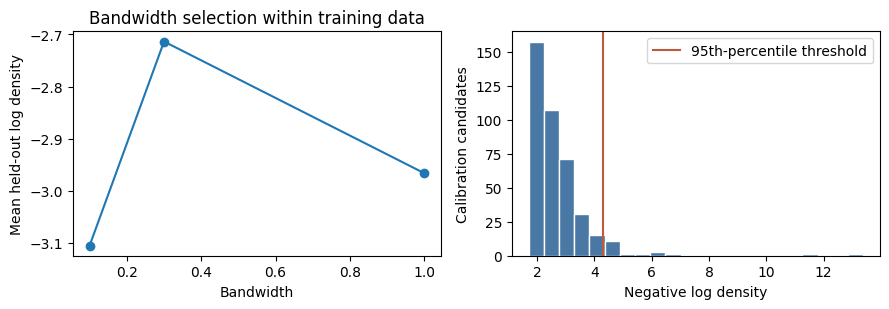

In [11]:
def calibrate_threshold(scores):
    # TODO 7
    scores = np.asarray(scores, dtype=float)
    tau = float(np.percentile(scores, 95))
    flags = scores > tau
    return tau, flags

check_tau, check_flags = calibrate_threshold(np.arange(21, dtype=float))
assert np.isclose(check_tau, 19.) and check_flags.sum() == 1
assert check_flags.dtype == np.bool_
tau, calibration_flags = calibrate_threshold(calibration_scores)
density_selection = {"bandwidth": selected_bandwidth, "threshold": float(tau)}
print("Fixed density choices:", density_selection)
print(f"Background calibration flags: {calibration_flags.sum()}/{len(calibration_flags)}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].plot(BANDWIDTHS, mean_cv_log_density, "o-")
axes[0].set(xlabel="Bandwidth", ylabel="Mean held-out log density",
            title="Bandwidth selection within training data")
axes[1].hist(calibration_scores, bins=22, color="#4978a5", edgecolor="white")
axes[1].axvline(tau, color="#be593d", label="95th-percentile threshold")
axes[1].set(xlabel="Negative log density", ylabel="Calibration candidates")
axes[1].legend()
fig.tight_layout()
plt.show()


**S2 (5 marks).**

(a) Why is a candidate's negative log density not its probability of being a pulsar?

(b) What does the 95th-percentile threshold mean for the background calibration
sample? Does it guarantee a 5% background false-alarm rate on test data?

**Answer:**

(a) The KDE is fitted **only to background candidates**. Its negative log density says how unusual a
candidate is compared with the background, not how likely it is to be a pulsar. It is not a probability.
It can be any real number and is not bounded in [0, 1]. A density can also exceed 1. Turning it into
P(pulsar) would also need a pulsar density and the class prior (Bayes' rule).

(b) By construction, about 5% of the 400 background calibration candidates score above tau (20 of 400
are flagged). That does **not** guarantee a 5% false-alarm rate on test data. The test background is a
different random sample, so its rate varies around 5%. The density and tau are also estimated from a
finite sample, and any shift between calibration and test data would change the rate. 5% is an
approximate target, not a guarantee.

### Fixed test evaluation
**TODO 8 (5 marks):** standardize the two test features using density_mean
and density_scale, score them with density_model, and flag scores strictly greater than tau.
Use the supplied detection_summary for the metrics. Keep the selected model
and threshold fixed.

**Define:** radio_test_scores, a NumPy array of shape (900,);
radio_test_flags, a Boolean NumPy array of shape (900,); and
radio_test_metrics, the dictionary returned by detection_summary.


Radio test results: {'tn': 764, 'fp': 36, 'fn': 22, 'tp': 78, 'precision': 0.6842105263157895, 'recall': 0.78, 'background_false_alarm_rate': 0.045}


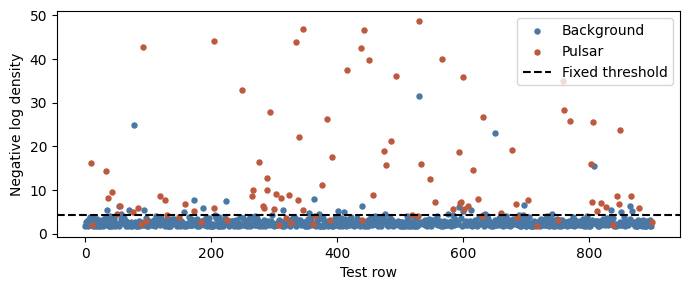

In [12]:
def detection_summary(actual, flagged):
    actual = np.asarray(actual, dtype=int)
    flagged = np.asarray(flagged, dtype=bool)
    tn = int(np.sum((actual == 0) & ~flagged))
    fp = int(np.sum((actual == 0) & flagged))
    fn = int(np.sum((actual == 1) & ~flagged))
    tp = int(np.sum((actual == 1) & flagged))
    return {"tn": tn, "fp": fp, "fn": fn, "tp": tp,
            "precision": tp / (tp + fp) if tp + fp else 0.,
            "recall": tp / (tp + fn) if tp + fn else 0.,
            "background_false_alarm_rate": fp / (tn + fp) if tn + fp else 0.}

with np.load(DATA_DIR / "htru2_small.npz", allow_pickle=False) as data:
    radio_X_test, radio_y_test = data["X_test"], data["y_test"]
# TODO 8
radio_test_U = apply_standardizer(radio_X_test[:, :2], density_mean, density_scale)
radio_test_scores = -density_model.score_samples(radio_test_U)
radio_test_flags = radio_test_scores > tau
radio_test_metrics = detection_summary(radio_y_test, radio_test_flags)

assert radio_test_scores.shape == radio_test_flags.shape == (900,)
assert radio_test_flags.dtype == np.bool_
assert np.isfinite(radio_test_scores).all()
assert sum(radio_test_metrics[k] for k in ("tn", "fp", "fn", "tp")) == 900
print("Radio test results:", radio_test_metrics)
fig, ax = plt.subplots(figsize=(7, 3))
for label, name, colour in [(0, "Background", "#4978a5"), (1, "Pulsar", "#be593d")]:
    selected = np.flatnonzero(radio_y_test == label)
    ax.scatter(selected, radio_test_scores[selected], s=13, label=name, color=colour)
ax.axhline(tau, color="black", linestyle="--", label="Fixed threshold")
ax.set(xlabel="Test row", ylabel="Negative log density")
ax.legend()
fig.tight_layout()
plt.show()


**R2 (5 marks).**

(a) Report test FP, FN, background false-alarm rate, and pulsar recall.

(b) What do a false positive and a false negative mean for this screening task?

**Answer:**

(a) On the 900 test candidates: **FP = 36**, **FN = 22** (TP = 78, TN = 764). Background false-alarm
rate = 36/800 = **4.5%**. Pulsar recall = 78/100 = **78%** (precision = 78/114, about 68.4%).

(b) A **false positive** is a background (non-pulsar) candidate flagged as unusual. It costs follow-up
time spent on noise or RFI. A **false negative** is a real pulsar the screen did not flag, because it
looks typical of the background in profile mean and standard deviation. That pulsar would be missed.
Here 22 of the 100 pulsars were missed.

## C. Fashion-MNIST: a small image classifier — 35 marks

Classify 28 × 28 grayscale images as 0 = T-shirt/top, 1 = Trouser,
or 2 = Bag. Training and validation samples come from the original training
set; the test sample comes from the original test set.

The training budget is fixed: 10 epochs, batch size 64, Adam with learning
rate 0.003. The supplied helper restores the epoch with the lowest validation CE.


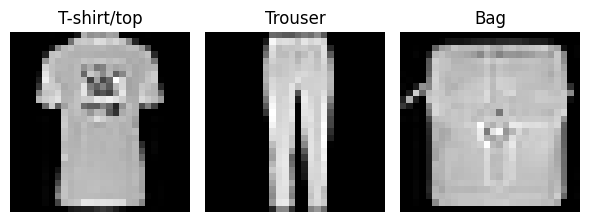

In [13]:
CLASS_NAMES = ["T-shirt/top", "Trouser", "Bag"]
with np.load(DATA_DIR / "fashion_small.npz", allow_pickle=False) as data:
    fashion_raw_train, fashion_raw_val = data["images_train"], data["images_val"]
    fashion_labels_train, fashion_labels_val = data["labels_train"], data["labels_val"]
assert fashion_raw_train.shape == (1200, 28, 28)
assert fashion_raw_val.shape == (300, 28, 28)
fig, axes = plt.subplots(1, 3, figsize=(6, 2.2))
for label, ax in enumerate(axes):
    i = np.flatnonzero(fashion_labels_train == label)[0]
    ax.imshow(fashion_raw_train[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(CLASS_NAMES[label])
    ax.axis("off")
fig.tight_layout()
plt.show()


**TODO 9 (5 marks):** convert the image arrays and class labels to tensors
for the CNN.
Given uint8 raw_images of shape (N, 28, 28)
and labels of shape (N,), **return (X, y)**.
X is a torch.float32 tensor of shape (N, 1, 28, 28), with pixel values
divided by 255. y is a torch.long tensor of shape (N,).


In [14]:
def image_tensors(raw_images, labels):
    # TODO 9
    X = torch.as_tensor(np.asarray(raw_images), dtype=torch.float32).unsqueeze(1) / 255.
    y = torch.as_tensor(np.asarray(labels), dtype=torch.long)
    return X, y

check_X, check_y = image_tensors(
    np.full((2, 28, 28), 255, dtype=np.uint8), np.array([0, 2]))
assert check_X.shape == (2, 1, 28, 28) and torch.all(check_X == 1)
assert check_X.dtype == torch.float32 and check_y.dtype == torch.long
assert check_y.shape == (2,) and check_y.tolist() == [0, 2]

fashion_X_train, fashion_y_train = image_tensors(fashion_raw_train, fashion_labels_train)
fashion_X_val, fashion_y_val = image_tensors(fashion_raw_val, fashion_labels_val)
train_loader = DataLoader(
    TensorDataset(fashion_X_train, fashion_y_train), batch_size=64, shuffle=True,
    generator=torch.Generator().manual_seed(SEED))
print("Training inputs and targets:", fashion_X_train.shape, fashion_y_train.shape)


Training inputs and targets: torch.Size([1200, 1, 28, 28]) torch.Size([1200])


**TODO 10 (8 marks):** build and return a new, untrained nn.Sequential network with these layers:

| Layer | Settings |
|---|---|
| Conv2d | 1 input channel, 8 output channels, kernel 3, padding 1 |
| ReLU | |
| MaxPool2d | kernel 2 |
| Conv2d | 8 input channels, 16 output channels, kernel 3, padding 1 |
| ReLU | |
| MaxPool2d | kernel 2 |
| Flatten | |
| Linear | 16 × 7 × 7 inputs, 3 outputs |

Use default stride and bias settings. The returned model maps input tensors
of shape (N, 1, 28, 28) to raw class scores of shape (N, 3).


In [15]:
def make_cnn():
    # TODO 10
    return nn.Sequential(
        nn.Conv2d(1, 8, kernel_size=3, padding=1),    # (N, 8, 28, 28)
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),                  # (N, 8, 14, 14)
        nn.Conv2d(8, 16, kernel_size=3, padding=1),   # (N, 16, 14, 14)
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),                  # (N, 16, 7, 7)
        nn.Flatten(),                                 # (N, 784)
        nn.Linear(16 * 7 * 7, 3),                     # (N, 3) raw class scores
    )

torch.manual_seed(SEED)
shape_model = make_cnn()
assert isinstance(shape_model, nn.Sequential)
assert shape_model(torch.zeros(5, 1, 28, 28)).shape == (5, 3)
assert sum(p.numel() for p in shape_model.parameters()) == 3603
print("Batch shape after each layer:")
check_batch = torch.zeros(64, 1, 28, 28)
for layer in shape_model:
    check_batch = layer(check_batch)
    print(type(layer).__name__, tuple(check_batch.shape))


Batch shape after each layer:
Conv2d (64, 8, 28, 28)
ReLU (64, 8, 28, 28)
MaxPool2d (64, 8, 14, 14)
Conv2d (64, 16, 14, 14)
ReLU (64, 16, 14, 14)
MaxPool2d (64, 16, 7, 7)
Flatten (64, 784)
Linear (64, 3)


**S3 (5 marks).**

(a) For a batch of 64 images, state the shapes after the first convolution,
the first pooling layer, the second pooling layer, and the final linear layer.

(b) How does a convolutional filter share its weights across image positions?

**Answer:**

(a) For a batch of 64 images (also printed by the shape check above):
- after the first convolution: **(64, 8, 28, 28)** (padding 1 keeps the 28 x 28 size)
- after the first pooling layer: **(64, 8, 14, 14)**
- after the second pooling layer: **(64, 16, 7, 7)**
- after the final linear layer: **(64, 3)**, one raw score per class

(b) Each filter is one small set of weights, for example 3 x 3 for each input channel plus a bias. The
same weights slide across every position in the image, and the dot product is computed at each location.
So a pattern such as an edge is detected the same way wherever it appears. This is why the first conv
layer has only 8 x (1 x 3 x 3) + 8 = 80 parameters, however large the image is.

### Supplied training helper
The two losses below evaluate the full training and validation samples
using the weights at the end of each epoch.


In [16]:
def cnn_loss(model, X, y):
    model.eval()
    with torch.no_grad():
        return float(nn.functional.cross_entropy(model(X), y))

def fit_cnn(model, loader, X_train, y_train, X_val, y_val):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
    history = {"train_ce": [], "val_ce": [], "best_epoch": None}
    best_loss, best_state = float("inf"), None
    for epoch in range(1, 11):
        model.train()
        for X_batch, y_batch in loader:
            optimizer.zero_grad()
            loss = nn.functional.cross_entropy(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()
        train_ce = cnn_loss(model, X_train, y_train)
        val_ce = cnn_loss(model, X_val, y_val)
        history["train_ce"].append(train_ce)
        history["val_ce"].append(val_ce)
        if val_ce < best_loss:
            best_loss = val_ce
            best_state = copy.deepcopy(model.state_dict())
            history["best_epoch"] = epoch
    model.load_state_dict(best_state)
    return history


**TODO 11 (4 marks):** create a fresh model with make_cnn, and call fit_cnn
with the supplied loader and training/validation tensors.

**Define:** fashion_model, the model restored by fit_cnn, and
fashion_history, its returned dictionary with train_ce, val_ce, and best_epoch.


Selected epoch: 8
Best validation CE: 0.12706413865089417


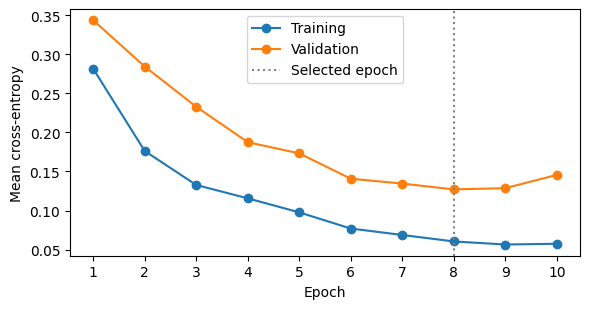

In [17]:
torch.manual_seed(SEED)
# TODO 11
fashion_model = make_cnn()
fashion_history = fit_cnn(fashion_model, train_loader, fashion_X_train, fashion_y_train,
                          fashion_X_val, fashion_y_val)

assert len(fashion_history["train_ce"]) == len(fashion_history["val_ce"]) == 10
assert fashion_history["best_epoch"] == int(np.argmin(fashion_history["val_ce"])) + 1
assert np.isclose(cnn_loss(fashion_model, fashion_X_val, fashion_y_val),
                  min(fashion_history["val_ce"]), atol=1e-7)
print("Selected epoch:", fashion_history["best_epoch"])
print("Best validation CE:", min(fashion_history["val_ce"]))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(range(1, 11), fashion_history["train_ce"], "o-", label="Training")
ax.plot(range(1, 11), fashion_history["val_ce"], "o-", label="Validation")
ax.axvline(fashion_history["best_epoch"], color="gray", linestyle=":", label="Selected epoch")
ax.set(xlabel="Epoch", ylabel="Mean cross-entropy")
ax.set_xticks(range(1, 11))
ax.legend()
fig.tight_layout()
plt.show()


### Evaluate the selected checkpoint
**TODO 12 (6 marks):** evaluate the selected CNN on the test images.
Within the supplied evaluation block, compute raw class scores, test CE,
predictions using argmax over the class dimension, and accuracy.

Use the restored fashion_model for this final evaluation.

**Define these four variables:**

| Variable | Required result |
|---|---|
| fashion_test_logits | PyTorch tensor of shape (600, 3), raw class scores |
| fashion_test_ce | Scalar test cross-entropy |
| fashion_test_predictions | Integer PyTorch tensor of shape (600,), predicted classes |
| fashion_test_accuracy | Scalar proportion correct, between 0 and 1 |


Fashion test CE: 0.0776
Fashion test accuracy: 97.83%


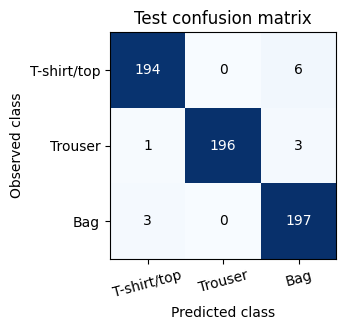

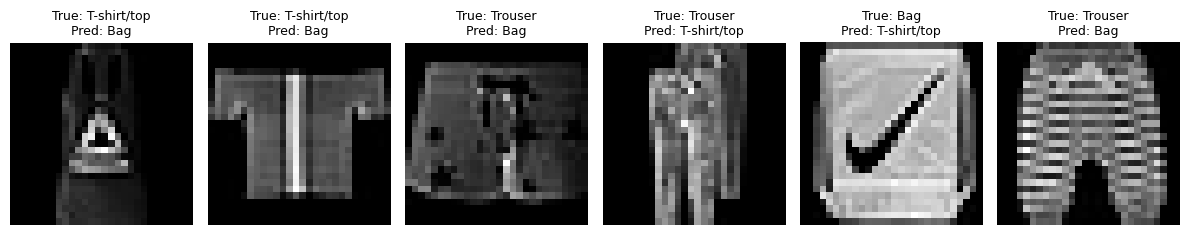

In [18]:
with np.load(DATA_DIR / "fashion_small.npz", allow_pickle=False) as data:
    fashion_raw_test, fashion_labels_test = data["images_test"], data["labels_test"]
fashion_X_test, fashion_y_test = image_tensors(fashion_raw_test, fashion_labels_test)
fashion_model.eval()
with torch.no_grad():
    # TODO 12
    fashion_test_logits = fashion_model(fashion_X_test)
    fashion_test_ce = float(nn.functional.cross_entropy(fashion_test_logits, fashion_y_test))
    fashion_test_predictions = fashion_test_logits.argmax(dim=1)
    fashion_test_accuracy = float((fashion_test_predictions == fashion_y_test).float().mean())

assert fashion_test_logits.shape == (600, 3)
assert fashion_test_predictions.shape == (600,)
assert torch.isfinite(fashion_test_logits).all()
assert 0 <= fashion_test_accuracy <= 1 and np.isfinite(fashion_test_ce)
print(f"Fashion test CE: {fashion_test_ce:.4f}")
print(f"Fashion test accuracy: {fashion_test_accuracy:.2%}")

fashion_confusion = np.zeros((3, 3), dtype=int)
np.add.at(fashion_confusion,
          (fashion_labels_test, fashion_test_predictions.cpu().numpy()), 1)
fig, ax = plt.subplots(figsize=(4.3, 3.4))
ax.imshow(fashion_confusion, cmap="Blues")
ax.set_xticks(range(3), CLASS_NAMES, rotation=15)
ax.set_yticks(range(3), CLASS_NAMES)
for i in range(3):
    for j in range(3):
        ax.text(j, i, str(fashion_confusion[i, j]), ha="center", va="center",
                color="white" if fashion_confusion[i, j] > 100 else "black")
ax.set(xlabel="Predicted class", ylabel="Observed class", title="Test confusion matrix")
fig.tight_layout()
plt.show()

fashion_error_indices = np.flatnonzero(
    fashion_test_predictions.cpu().numpy() != fashion_labels_test)[:6]
if len(fashion_error_indices):
    fig, axes = plt.subplots(1, len(fashion_error_indices),
                             figsize=(2 * len(fashion_error_indices), 2.5), squeeze=False)
    for ax, i in zip(axes.flat, fashion_error_indices):
        pred = int(fashion_test_predictions[i])
        ax.imshow(fashion_raw_test[i], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"True: {CLASS_NAMES[int(fashion_labels_test[i])]}\nPred: {CLASS_NAMES[pred]}",
                     fontsize=9)
        ax.axis("off")
    fig.tight_layout()
    plt.show()
else:
    print("No test errors in this run.")


In [19]:
# Helper for R3: print the numbers used in the answer below
train_ce, val_ce = np.array(fashion_history["train_ce"]), np.array(fashion_history["val_ce"])
print(f"Min training CE:   epoch {train_ce.argmin() + 1}, CE {train_ce.min():.4f}")
print(f"Min validation CE: epoch {val_ce.argmin() + 1}, CE {val_ce.min():.4f}")
bag_tp = fashion_confusion[2, 2]
bag_fp = fashion_confusion[0, 2] + fashion_confusion[1, 2]
bag_fn = fashion_confusion[2, 0] + fashion_confusion[2, 1]
print("Confusion matrix (rows observed, columns predicted):\n", fashion_confusion)
print(f"Bag TP={bag_tp}, FP={bag_fp}, FN={bag_fn}")
print(f"Bag precision={bag_tp / (bag_tp + bag_fp):.4f}, recall={bag_tp / (bag_tp + bag_fn):.4f}")


Min training CE:   epoch 9, CE 0.0566
Min validation CE: epoch 8, CE 0.1271
Confusion matrix (rows observed, columns predicted):
 [[194   0   6]
 [  1 196   3]
 [  3   0 197]]
Bag TP=197, FP=9, FN=3
Bag precision=0.9563, recall=0.9850


**R3 (7 marks).**

(a) Using fashion_history, report the epoch and CE at the minimum training CE
and at the minimum validation CE. Which checkpoint should be used for final
test predictions, and why?

(b) Treat Bag as the positive class and the other classes as negative.
Calculate precision and recall from the test confusion matrix.
Are false Bag predictions or missed Bags more frequent?
Support your answer with the counts.

**Answer:**

(a) Minimum **training** CE: **epoch 9, CE 0.0566**. Minimum **validation** CE: **epoch 8, CE 0.1271**.
Final test predictions should use the **epoch 8 checkpoint** (lowest validation CE), which fit_cnn
restores. Training CE keeps falling as the model fits the training images more closely, so a low training
CE does not show how the model handles new images. At epoch 9 training CE was lower, but validation CE
was not. Validation images were never used for weight updates, so validation CE estimates generalization.
That makes epoch 8 the better choice. The test set is used only once, for this final evaluation
(test CE 0.0776, accuracy 97.83%).

(b) With Bag (row/column 2) as positive, from the test confusion matrix:
- TP = 197 (Bags predicted as Bag)
- FP = 6 + 3 = **9** (6 T-shirts/tops and 3 Trousers predicted as Bag)
- FN = 3 + 0 = **3** (3 Bags predicted as T-shirt/top)

Precision = 197 / (197 + 9) = 197/206 = **0.956**. Recall = 197 / (197 + 3) = 197/200 = **0.985**.
**False Bag predictions are more frequent than missed Bags**: 9 vs 3. The model rarely misses a real
Bag, but it sometimes labels other items as Bags, mostly T-shirts/tops (6 of the 9).

## Submission

Submit **one file: executed.pdf**, with every page in A4 format.
Include the complete notebook in order: code, outputs, figures, and S/R answers.

1. Complete the TODOs and answers. Restart the kernel, run all cells, and save.
2. Export the notebook to HTML with code and outputs visible, saving it as
   individual_project_3.html in the project folder, beside prepare_pdf.py.
3. Open a terminal in that folder and run:

       python3 prepare_pdf.py ./individual_project_3.html

4. Open the generated executed.html and print to PDF: A4, 100% scale,
   default margins, browser headers and footers off.
5. Inspect the saved PDF for complete, readable code, results, and figures.
   Submit executed.pdf and keep your notebook locally.

**Data attribution:** HTRU2: Lyon (2015), [UCI](https://doi.org/10.24432/C5DK6R),
CC BY 4.0. Fashion-MNIST: Xiao, Rasul, and Vollgraf (2017),
[Zalando Research](https://github.com/zalandoresearch/fashion-mnist), MIT.
See the data guide and attribution file for details.
